# dopplerloc walkthrough: from a recording to a position on the map

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/jmarcoz1/doppler-geolocate/main?labpath=notebooks%2Fwalkthrough.ipynb)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jmarcoz1/doppler-geolocate/blob/main/notebooks/walkthrough.ipynb)

This notebook walks through the whole chain one step at a time:

1. load the audio (default: the synthetic recording near Valencia airport, LEVC, generated if missing)
2. raw spectrogram
3. cleaning, one stage at a time: band-pass → mains-hum notches → noise-floor subtraction → tonal-line enhancement → reassigned spectrogram
4. Doppler ridge extraction
5. progressive localisation: coarse grid → medium grid → fine grid → exact least squares (position + clock offset)
6. fitted Doppler model vs the extracted curves
7. Lloyd's-mirror ground-reflection fringes → microphone height
8. the location likelihood refined step by step on a real OpenStreetMap map, with ADS-B tracks, the true position, and the estimate

**Interactive vs static.** Every figure is first drawn statically with default parameters, so the
notebook still reads correctly on GitHub or nbviewer, or after `nbconvert`. When `ipywidgets` is
available in a live kernel, a set of sliders follows each static figure (STFT window, hum notch on/off,
noise-floor percentile, ridge threshold, grid resolution, and a play/step slider for the map refinement).

Install: `pip install -e ".[notebook]"` (adds jupyter, ipywidgets, folium). In Colab, the first code
cell clones the repository and installs it.

In [1]:
# Colab / Binder bootstrap: install the package if it is not importable yet
import importlib.util, os, subprocess, sys
if importlib.util.find_spec("dopplerloc") is None:
    if not os.path.exists("doppler-geolocate"):
        subprocess.run(["git", "clone", "-q", "https://github.com/jmarcoz1/doppler-geolocate"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "doppler-geolocate[notebook]"], check=True)
    sys.path.insert(0, os.path.abspath("doppler-geolocate"))
    os.chdir("doppler-geolocate")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                       # run from the repo root so relative paths work
print("working directory:", os.getcwd())

working directory: /workspace/doppler-geolocate


In [2]:
import os
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, HTML, display

from dopplerloc import audio, cleaning, geodesy, lloyd, pipeline, simulate, tracks
from dopplerloc import ridge as ridge_mod
from dopplerloc.physics import Observer, Propagation, doppler_factor, emission_time, lloyd_delay
from dopplerloc.progressive import progressive_locate

try:
    import ipywidgets as W
    # headless execution (nbconvert/CI): widget callbacks drawing matplotlib into Output widgets make
    # nbclient wait for its full timeout, so the saved notebook keeps the static figures only
    HAVE_WIDGETS = not os.environ.get("DOPPLERLOC_HEADLESS")
except ImportError:              # static fallback: figures below still render with defaults
    HAVE_WIDGETS = False
try:
    import folium  # noqa: F401
    from dopplerloc import webmap
    HAVE_FOLIUM = True
except ImportError:
    HAVE_FOLIUM = False
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (12, 4.5)})
print(f"ipywidgets: {HAVE_WIDGETS}   folium: {HAVE_FOLIUM}")

def quiet(f):
    # interact() would display the return value; widgets only need the figure
    return lambda **k: (f(**k), None)[1]

def spec_ax(ax, S, fmax=2200, vmin_pct=20, vmax_pct=99.7, title="", cmap="magma"):
    m = S.freqs <= fmax
    db = S.db[m]
    vmin, vmax = np.percentile(db, [vmin_pct, vmax_pct])
    ax.pcolormesh(S.times, S.freqs[m], db, shading="auto", cmap=cmap, vmin=vmin, vmax=vmax, rasterized=True)
    ax.set_ylabel("Hz"); ax.set_title(title, fontsize=10)
    return ax

ipywidgets: False   folium: True


## 1. Load the audio

Default: `outputs/synthetic_recording.wav`. This is 150 s at 8 kHz, rendered physically for a hidden
observer about 6 km north-west of LEVC. It contains two audible aircraft (an RWY12 arrival and a
climbing departure that turns), a 50 Hz mains hum with harmonics, wind rumble, and ground reflection.
The ADS-B tracks the solver gets are in `outputs/synthetic_adsb_tracks.parquet`, which also contains
an inaudible high-altitude distractor. If either file is missing, it is regenerated.

To use your own recording, set `AUDIO_PATH`, `TRACKS_PATH`, `T_START` (the recording start as unix
time, with ±2 s accuracy) and `CENTER` (the centre of the search area).

In [3]:
AUDIO_PATH = None      # e.g. "my_recording.wav"; None -> synthetic demo
TRACKS_PATH = None     # parquet/csv from `python -m dopplerloc fetch ...`
T_START = None         # unix time of the first sample (nominal, from the recorder clock)
CENTER = None          # (lat, lon) centre of the search area

sc = simulate.scenario()
truth = None
if AUDIO_PATH is None:
    wav, trk = Path("outputs/synthetic_recording.wav"), Path("outputs/synthetic_adsb_tracks.parquet")
    if not wav.exists() or not trk.exists():
        print("generating synthetic recording + ADS-B tracks ...")
        wav.parent.mkdir(exist_ok=True)
        x, sr, _ = simulate.synthesize(sc, seed=7)
        audio.save_wav(wav, x, sr)
        tracks.save_tracks(simulate.adsb_samples(sc, seed=1), trk)
    AUDIO_PATH, TRACKS_PATH = wav, trk
    T_START = sc["t_rec0"] + 1.3        # the synthetic recorder clock runs 1.3 s fast (unknown to the solver)
    CENTER = simulate.LEVC[:2]
    truth = sc["observer"]              # hidden from the solver, used only for grading and drawing
x, sr = audio.load_audio(AUDIO_PATH)
df_tracks = tracks.load_tracks(TRACKS_PATH)
H_OBS = truth.h if truth is not None else 0.0   # ellipsoidal ground+mic height (from a DEM in real use)
print(f"{AUDIO_PATH}: {len(x)/sr:.1f} s @ {sr} Hz;  {df_tracks.icao24.nunique()} aircraft in {TRACKS_PATH}")
i0 = int(35 * sr)
display(Audio(x[i0:i0 + 20 * sr], rate=sr))    # 20 s excerpt around the first closest approach

outputs/synthetic_recording.wav: 150.0 s @ 8000 Hz;  3 aircraft in outputs/synthetic_adsb_tracks.parquet


## 2. Raw spectrogram

STFT with a Hann window. A longer window gives finer frequency resolution (Δf ≈ sr / n_fft) but
smears the fast Doppler swing at closest approach. The default, 4096 samples (0.51 s), zero-padded
to 8192, gives ~1 Hz bins. Already visible here: the descending Doppler "S-curves" of the tones, the
broadband hump with interference fringes (from ground reflection), and the horizontal 50 Hz hum lines.

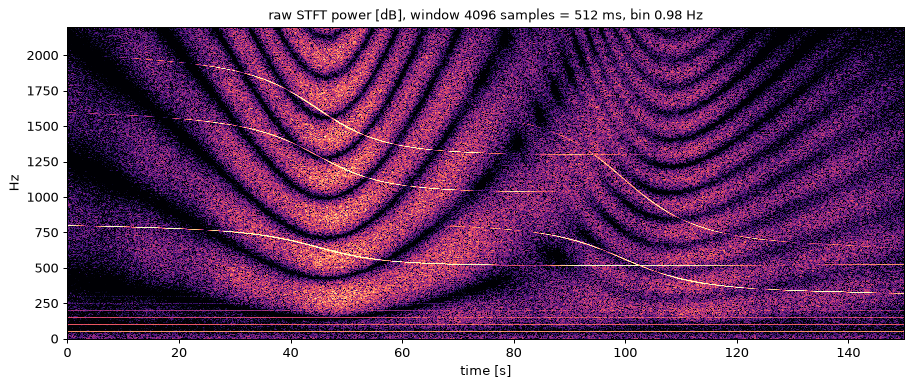

In [4]:
def raw_spec(win=4096):
    S = audio.stft(x, sr, win_length=win, hop=400, n_fft=max(8192, 2 * win))
    fig, ax = plt.subplots(figsize=(12, 4.5))
    spec_ax(ax, S, title=f"raw STFT power [dB], window {win} samples = {win/sr*1e3:.0f} ms, bin {S.df:.2f} Hz")
    ax.set_xlabel("time [s]"); plt.show()
    return S

S_raw = raw_spec(4096)

In [5]:
if HAVE_WIDGETS:
    W.interact(quiet(raw_spec), win=W.SelectionSlider(options=[512, 1024, 2048, 4096, 8192], value=4096,
                                               description="STFT window", continuous_update=False));

## 3. Cleaning, one stage at a time

| stage | domain | what it removes |
|---|---|---|
| a. band-pass (zero-phase Butterworth) | waveform | wind rumble and very low frequencies |
| b. mains-hum notches at k·f₀ (f₀ tracked around 50 Hz) | waveform | 50 Hz hum and its harmonics |
| c. noise-floor subtraction (per-frequency low percentile over time) | spectrogram | stationary background, whitening |
| d. tonal-line enhancement (minus the running median across frequency) | spectrogram | broadband jet noise and fringes; leaves narrow lines |
| e. reassigned spectrogram (optional) | spectrogram | smearing: each cell's energy moves to its instantaneous frequency |

The noise-floor percentile is deliberately low (20 %). With the median, a Doppler plateau that sits
in the same bins for most of the recording would be mistaken for background.

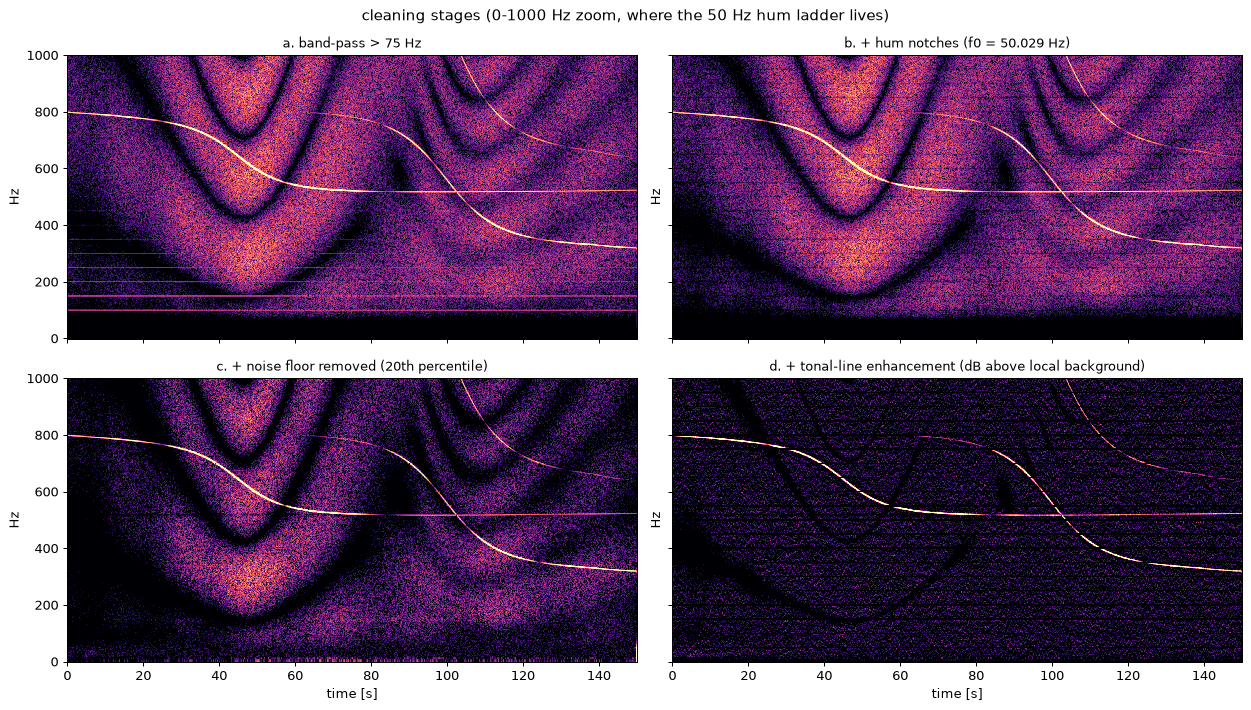

In [6]:
def cleaning_stages(win=4096, hum_notch=True, floor_pct=20.0, fmin=75.0, show=True):
    nfft = max(8192, 2 * win)
    y_bp = cleaning.bandpass(x, sr, fmin, None)
    f0 = cleaning.estimate_mains_f0(y_bp, sr, 50.0)
    y_hum = cleaning.remove_mains_hum(y_bp, sr, 50.0) if hum_notch else y_bp
    S_bp = audio.stft(y_bp, sr, win_length=win, hop=400, n_fft=nfft)
    S_hum = audio.stft(y_hum, sr, win_length=win, hop=400, n_fft=nfft)
    S_floor = cleaning.subtract_noise_floor(S_hum, floor_pct)
    S_line = cleaning.enhance_tonal(S_floor)
    if hum_notch:
        S_line = cleaning.suppress_stationary_lines(S_line, 50.0, 2.5)
    out = dict(S_bp=S_bp, S_hum=S_hum, S_floor=S_floor, S_line=S_line, f0=f0)
    if show:
        fig, axs = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)
        spec_ax(axs[0, 0], S_bp, fmax=1000, title=f"a. band-pass > {fmin:.0f} Hz")
        spec_ax(axs[0, 1], S_hum, fmax=1000, title=("b. + hum notches (f0 = %.3f Hz)" % f0) if hum_notch else "b. hum notch OFF")
        spec_ax(axs[1, 0], S_floor, fmax=1000, vmin_pct=40, title=f"c. + noise floor removed ({floor_pct:.0f}th percentile)")
        spec_ax(axs[1, 1], S_line, fmax=1000, vmin_pct=50, title="d. + tonal-line enhancement (dB above local background)")
        for a in axs[1]: a.set_xlabel("time [s]")
        fig.suptitle("cleaning stages (0-1000 Hz zoom, where the 50 Hz hum ladder lives)"); fig.tight_layout(); plt.show()
    return out

CL = cleaning_stages()

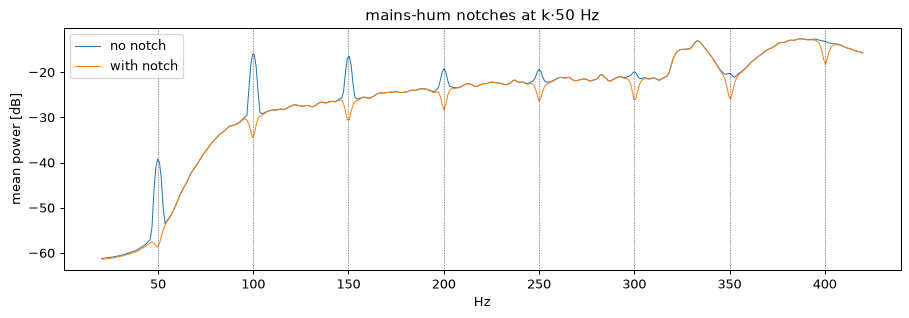

In [7]:
# zoom on the hum: mean spectrum over the recording before/after the notch filter
def hum_zoom(win=4096):
    a = cleaning_stages(win, True, show=False); b = cleaning_stages(win, False, show=False)
    fig, ax = plt.subplots(figsize=(12, 3.5))
    for S, lab in ((b["S_hum"], "no notch"), (a["S_hum"], "with notch")):
        m = (S.freqs > 20) & (S.freqs < 420)
        ax.plot(S.freqs[m], 10 * np.log10(S.power[m].mean(1)), lw=0.8, label=lab)
    for k in range(1, 9): ax.axvline(50 * k, color="k", ls=":", lw=0.5)
    ax.set_xlabel("Hz"); ax.set_ylabel("mean power [dB]"); ax.legend(); ax.set_title("mains-hum notches at k·50 Hz"); plt.show()
hum_zoom()

In [8]:
if HAVE_WIDGETS:
    W.interact(quiet(cleaning_stages),
               win=W.SelectionSlider(options=[1024, 2048, 4096, 8192], value=4096, description="STFT window", continuous_update=False),
               hum_notch=W.Checkbox(value=True, description="hum notch"),
               floor_pct=W.FloatSlider(value=20, min=5, max=60, step=5, description="floor pct", continuous_update=False),
               fmin=W.FloatSlider(value=75, min=20, max=300, step=5, description="high-pass Hz", continuous_update=False),
               show=W.fixed(True));

### 3e. Reassigned spectrogram

Reassignment (Auger & Flandrin 1995) moves each cell's energy to its local instantaneous frequency
and group delay. Tonal lines become much sharper, which helps when two harmonics are close together
or when the Doppler slope at closest approach is steep.

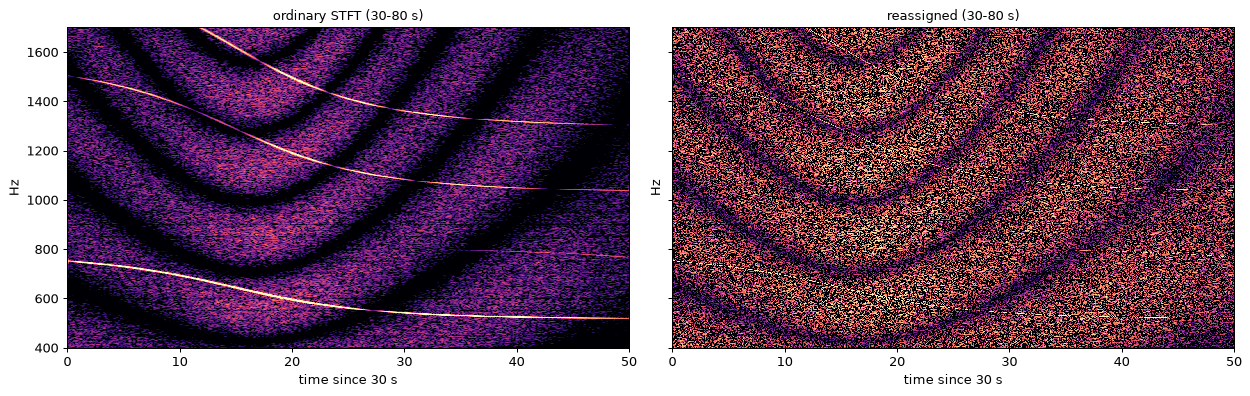

In [9]:
def reassigned_view(win=4096, t0=30.0, t1=80.0):
    y = cleaning.remove_mains_hum(cleaning.bandpass(x, sr, 75.0), sr, 50.0)
    seg = y[int(t0 * sr):int(t1 * sr)]
    S1 = audio.stft(seg, sr, win_length=win, hop=200, n_fft=2 * win)
    S2 = audio.reassigned_spectrogram(seg, sr, win_length=win, hop=200, n_fft=2 * win)
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for a, S, t in ((axs[0], S1, "ordinary STFT"), (axs[1], S2, "reassigned")):
        spec_ax(a, S, fmax=1700, vmin_pct=40, title=f"{t} ({t0:.0f}-{t1:.0f} s)")
        a.set_ylim(400, 1700); a.set_xlabel(f"time since {t0:.0f} s")
    fig.tight_layout(); plt.show()
reassigned_view()

In [10]:
if HAVE_WIDGETS:
    W.interact(quiet(reassigned_view), win=W.SelectionSlider(options=[1024, 2048, 4096], value=4096, description="window", continuous_update=False),
               t0=W.FloatSlider(value=30, min=0, max=120, step=5, continuous_update=False),
               t1=W.FloatSlider(value=80, min=20, max=150, step=5, continuous_update=False));

## 4. Doppler ridge extraction

Ridges are traced by Viterbi dynamic programming through the line-enhanced spectrogram. Each step
maximises (dB above background) minus a penalty on frequency jumps, the slope is capped at 40 Hz/s,
the confident segments are kept, and the frequency is refined to sub-bin precision. Stationary lines
are rejected (hum, a fridge, an insect). The **ridge threshold** is the minimum line SNR, in dB above
the local background, for a frame to count as part of a ridge.

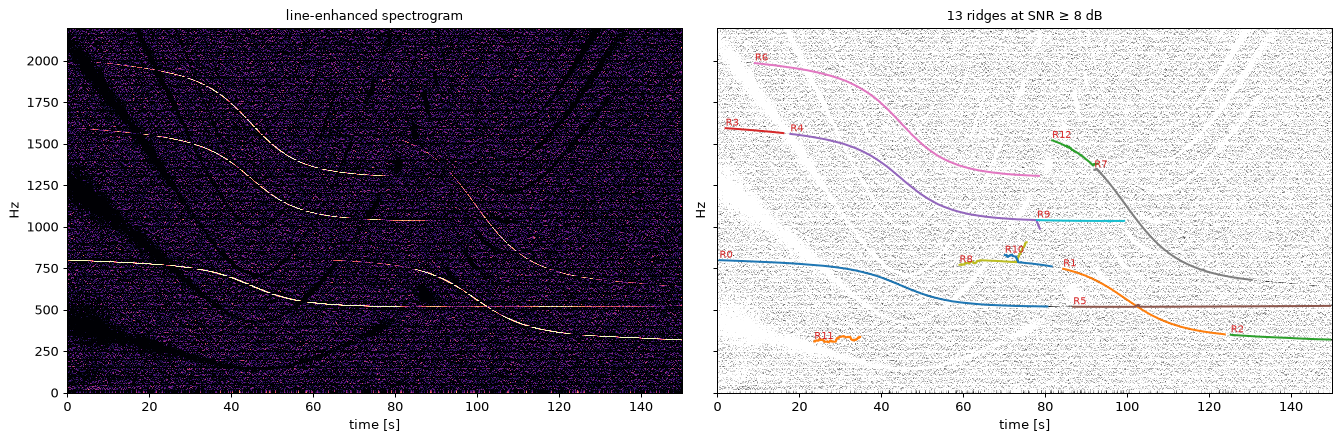

ridges: [('R0', '0-81s', '519-798Hz'), ('R1', '84-124s', '351-746Hz'), ('R2', '125-150s', '320-349Hz'), ('R3', '2-16s', '1563-1594Hz'), ('R4', '18-79s', '987-1559Hz'), ('R5', '87-150s', '517-529Hz'), ('R6', '9-78s', '1305-1986Hz'), ('R7', '92-130s', '680-1349Hz'), ('R8', '59-76s', '770-906Hz'), ('R9', '78-99s', '1031-1040Hz'), ('R10', '70-82s', '761-831Hz'), ('R11', '24-35s', '303-341Hz'), ('R12', '82-93s', '1368-1520Hz')]


In [11]:
CFG = pipeline.ExtractConfig()
def extract(threshold_db=8.0, win=4096, hum_notch=True, floor_pct=20.0, show=True):
    c = cleaning_stages(win, hum_notch, floor_pct, show=False)
    rid = ridge_mod.extract_ridges(c["S_line"], n_ridges=CFG.n_ridges, fmin=CFG.fmin, fmax=CFG.fmax,
                                   max_slope_hz_s=CFG.max_slope_hz_s, snr_threshold_db=threshold_db,
                                   min_duration_s=CFG.min_duration_s, refine_db=c["S_hum"].db)
    if show:
        fig, axs = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
        spec_ax(axs[0], c["S_line"], vmin_pct=50, title="line-enhanced spectrogram")
        spec_ax(axs[1], c["S_line"], vmin_pct=50, cmap="gray_r", title=f"{len(rid)} ridges at SNR ≥ {threshold_db:.0f} dB")
        for r in rid:
            axs[1].plot(r.t, r.f, lw=1.6); axs[1].text(r.t[0], r.f[0] + 15, r.label, fontsize=8, color="C3")
        for a in axs: a.set_xlabel("time [s]")
        fig.tight_layout(); plt.show()
    return rid, c

ridges, CL = extract()
print("ridges:", [(r.label, f"{r.t[0]:.0f}-{r.t[-1]:.0f}s", f"{r.f.min():.0f}-{r.f.max():.0f}Hz") for r in ridges])

In [12]:
if HAVE_WIDGETS:
    W.interact(quiet(extract), threshold_db=W.FloatSlider(value=8, min=3, max=20, step=1, description="ridge thr dB", continuous_update=False),
               win=W.SelectionSlider(options=[2048, 4096, 8192], value=4096, description="STFT window", continuous_update=False),
               hum_notch=W.Checkbox(value=True, description="hum notch"),
               floor_pct=W.FloatSlider(value=20, min=5, max=60, step=5, description="floor pct", continuous_update=False),
               show=W.fixed(True));

## 5. Progressive localisation

The forward model: for a trial microphone position and clock offset, solve for the retarded emission
time `t_e` of every ADS-B track (`t_obs = t_e + R(t_e)/c`, with the ISA sound speed). The heard
frequency is then `f_src · c / (c + v_r)`. Each ridge is assigned to whichever aircraft explains it
best, and its unknown source frequency `f_src` is projected out in closed form. The misfit χ² over all
ridges, plus a Gaussian prior on the clock offset (±2 s), defines the likelihood:

1. **coarse grid** over the whole search area (±12 km); the grid step is the main speed/accuracy knob
2. **medium grids** around the best few separated coarse minima, ranked by the exact global score.
   This guards against mirror solutions on the other side of a straight track.
3. **fine grid** around the winner
4. **exact least squares** over (east, north, clock offset), with soft-L1 → L2, outlier-ridge rejection,
   and a clock/along-track polish (clock offset and along-track position trade off, which caused the
   147 m miss seen earlier). Then a Lloyd's-mirror term for the mic height.

Runtime: about 1 minute at the default 1200 m coarse step.

In [13]:
models_all = tracks.build_models(df_tracks, geoid_n=0.0)
prop = Propagation()
S_full = audio.stft(cleaning.clean_pipeline(x, sr, fmin=75.0, mains=50.0), sr, win_length=4096, hop=400, n_fft=8192)
fringe = lloyd.cepstral_delay(S_full, fmin=150.0, fmax=2500.0)
STAGES = {}
def run_locate(coarse_step_m=1200.0):
    if coarse_step_m not in STAGES:
        T = time.time()
        STAGES[coarse_step_m] = progressive_locate(ridges, models_all, T_START, CENTER, half_width_m=12000.0,
                                                   coarse_step_m=coarse_step_m, h_obs=H_OBS, dt_sigma=2.0,
                                                   prop=prop, fringe=fringe)
        print(f"total {time.time() - T:.0f} s")
    return STAGES[coarse_step_m]

stages, models = run_locate(1200.0)
res = stages[-1].result
if truth is not None:
    for s in stages:
        print(f"{s.name:28s} error vs truth: {geodesy.haversine_m(s.lat, s.lon, truth.lat, truth.lon):8.1f} m")

[1 coarse grid (1200 m)] best 39.52173,-0.57924 dt=-4.00s  (8.5 s) 441 cells, 2 aircraft


[2 medium grid (300 m)] best 39.52713,-0.57576 dt=-3.50s  (16.3 s) 2 candidate basins, scores [96833.8, 218859.8]


[3 fine grid (100 m)] best 39.52713,-0.57343 dt=-2.00s  (10.7 s) 


[4 least squares] best 39.52694,-0.57322 dt=-1.26s  (27.3 s) 9/13 ridges used, rms 1.93 Hz, h_r 1.27 m
total 63 s
1 coarse grid (1200 m)       error vs truth:    779.8 m
2 medium grid (300 m)        error vs truth:    214.9 m
3 fine grid (100 m)          error vs truth:     20.7 m
4 least squares              error vs truth:      7.4 m


### Grid-resolution control (live kernel only)

Changing the coarse step re-runs the whole solve, which takes up to a few minutes, so this one runs
on a button (`interact_manual`). Results are cached per step.

In [14]:
if HAVE_WIDGETS:
    def _rerun(coarse_step_m):
        st, _ = run_locate(float(coarse_step_m))
        if truth is not None:
            print(f"final error {geodesy.haversine_m(st[-1].lat, st[-1].lon, truth.lat, truth.lon):.1f} m")
    W.interact_manual(quiet(_rerun), coarse_step_m=W.SelectionSlider(options=[3000, 2400, 1800, 1200, 800, 600], value=1200,
                                                              description="coarse grid m"));

## 6. Doppler model fit vs extracted curves

At the final position and clock offset, the predicted `f_obs(t)` of each assigned aircraft (black)
is drawn over the measured ridges. The bottom panel shows the residuals. Ridges rejected as outliers
(typically a ridge that jumped between two crossing tones) are grey crosses.

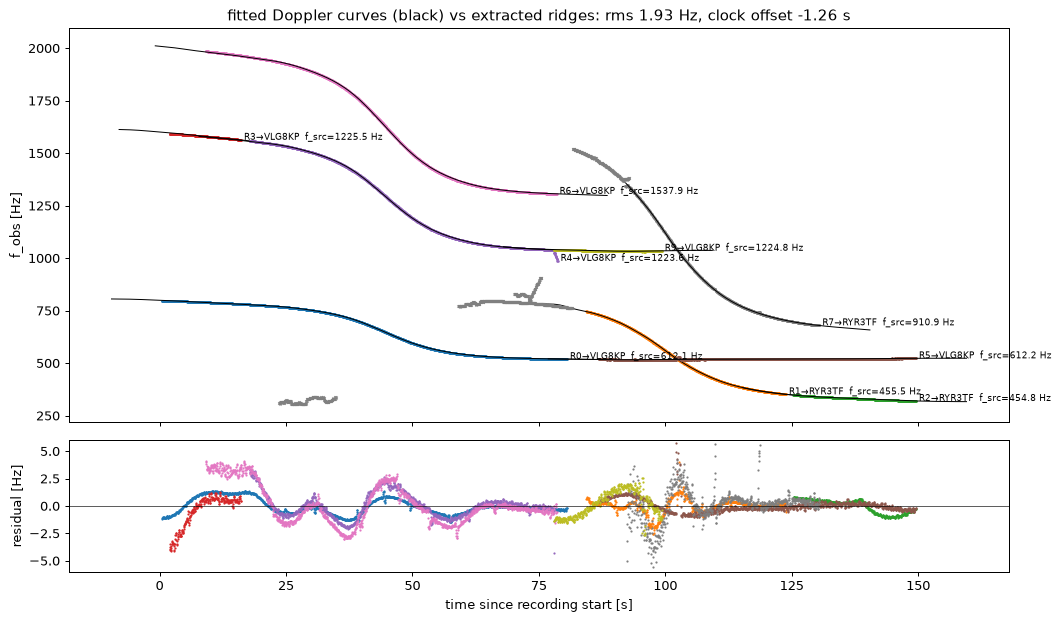

In [15]:
def doppler_fit_plot(res, models, show_rejected=True):
    ob = Observer(res.lat, res.lon, res.h)
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
    for k, i in enumerate(res.used_ridges):
        r, m = ridges[i], models[res.assignment[k]]
        tt = np.linspace(r.t[0] - 10, r.t[-1] + 10, 400)
        _, g = emission_time(m, ob, T_START + res.dt + tt, prop)
        _, g2 = emission_time(m, ob, T_START + res.dt + r.t, prop)
        pred = res.f_src[k] * doppler_factor(g2["vr"], g2["c"])
        ax.plot(r.t, r.f, ".", ms=2, color=f"C{k % 10}")
        ax.plot(tt, res.f_src[k] * doppler_factor(g["vr"], g["c"]), "k-", lw=0.8)
        ax.text(r.t[-1], r.f[-1], f" {r.label}→{m.callsign}  f_src={res.f_src[k]:.1f} Hz", fontsize=7)
        axr.plot(r.t, r.f - pred, ".", ms=1.5, color=f"C{k % 10}")
    if show_rejected:
        for i, r in enumerate(ridges):
            if i not in res.used_ridges:
                ax.plot(r.t, r.f, "x", ms=2, color="grey", alpha=0.6)
    ax.set_ylabel("f_obs [Hz]"); axr.set_ylabel("residual [Hz]"); axr.set_xlabel("time since recording start [s]")
    axr.axhline(0, color="k", lw=0.5); axr.set_ylim(-6, 6)
    ax.set_title(f"fitted Doppler curves (black) vs extracted ridges: rms {res.rms_hz:.2f} Hz, clock offset {res.dt:+.2f} s")
    fig.tight_layout(); plt.show()
doppler_fit_plot(res, models)

## 7. Lloyd's-mirror fringes → microphone height

The microphone hears the direct ray plus a ground reflection delayed by τ ≈ 2·h_r·sin(elevation)/c.
This multiplies the broadband spectrum by a comb, which shows up as the sweeping "fringes". The
cepstrum of each frame measures τ(t). With the geometry fixed by the solved position and the ADS-B
tracks, τ(t) depends on a single parameter, the microphone height h_r.

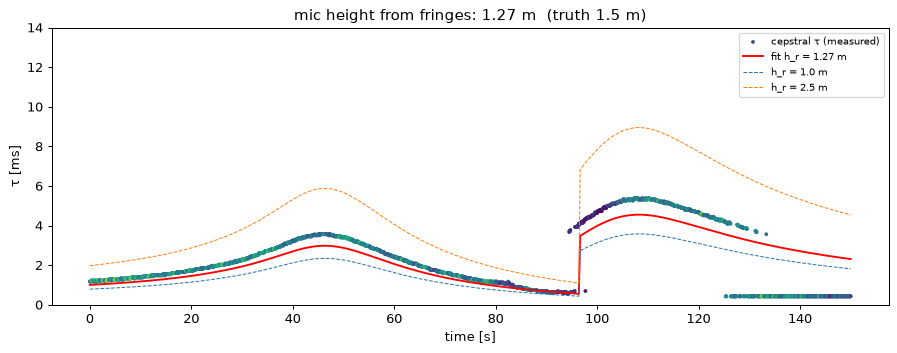

In [16]:
def fringe_plot(res, models, h_alt=(1.0, 2.5)):
    ob = Observer(res.lat, res.lon, res.h)
    tt = np.linspace(0, S_full.times[-1], 600)
    Rs, Ps, cs = [], [], []
    for mi in sorted(set(res.assignment)):
        _, g = emission_time(models[mi], ob, T_START + res.dt + tt, prop)
        Rs.append(g["R"]); Ps.append(g["P"]); cs.append(g["c"])
    near = np.argmin(np.stack(Rs), 0)
    def tau_of(h):
        return np.stack([lloyd_delay(P, ob, h, c) for P, c in zip(Ps, cs)])[near, np.arange(len(tt))]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(fringe.t, fringe.tau * 1e3, s=4, c=fringe.strength, cmap="viridis", label="cepstral τ (measured)")
    ax.plot(tt, tau_of(res.h_receiver) * 1e3, "r-", lw=1.5, label=f"fit h_r = {res.h_receiver:.2f} m")
    for h in h_alt:
        ax.plot(tt, tau_of(h) * 1e3, "--", lw=0.8, label=f"h_r = {h} m")
    ax.set_ylim(0, 14); ax.set_xlabel("time [s]"); ax.set_ylabel("τ [ms]"); ax.legend(fontsize=8)
    t = f"mic height from fringes: {res.h_receiver:.2f} m" + (f"  (truth {sc['h_receiver']} m)" if truth is not None else "")
    ax.set_title(t); plt.show()
fringe_plot(res, models)

## 8. The map: likelihood refined step by step

Colour shows the misfit relative to the best cell, −log₁₀(χ²/χ²_min) (bright = likely; cells more
than 1.5 decades worse are transparent). Each stage zooms in on the previous winner, and the dashed
white line traces the estimate through the stages. Orange lines are the ADS-B tracks during the
recording, the red ellipse is the formal 95 % ellipse, and the green star is the hidden true position.

First comes a static matplotlib version (renders anywhere), then the Leaflet/OSM map with one
layer per stage (use the layer control), then a play/step slider that builds the map stage by stage.

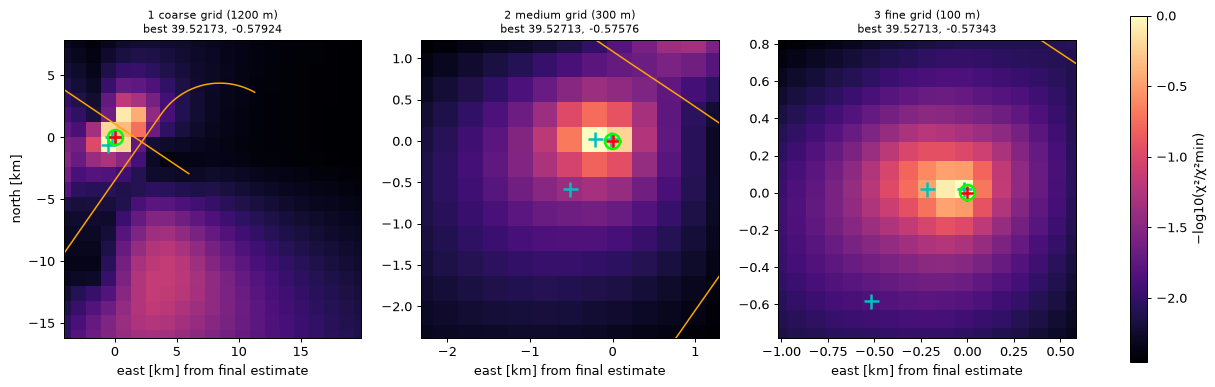

In [17]:
T_WIN = (T_START - 30, T_START + len(x) / sr + 30)
def stage_panels(stages, models):
    n = len([s for s in stages if s.grid is not None])
    fig, axs = plt.subplots(1, n, figsize=(5.2 * n, 5))
    lat0, lon0 = stages[-1].lat, stages[-1].lon
    for ax, s in zip(axs, [s for s in stages if s.grid is not None]):
        g = s.grid
        E = geodesy.geodetic_to_enu(g.lat, g.lon, 0 * g.lat, lat0, lon0, 0) / 1e3
        z = -np.log10(g.chi2 / g.chi2.min())
        im = ax.pcolormesh(E[..., 0], E[..., 1], np.clip(z, -3, 0), shading="auto", cmap="magma")
        for m in models:
            tt = np.linspace(*T_WIN, 400); la, lo, _ = m.geodetic(tt)
            pe = geodesy.geodetic_to_enu(la, lo, 0 * la, lat0, lon0, 0) / 1e3
            ax.plot(pe[:, 0], pe[:, 1], "-", color="orange", lw=1.2)
        for q in stages:
            pe = geodesy.geodetic_to_enu(q.lat, q.lon, 0, lat0, lon0, 0) / 1e3
            ax.plot(pe[0], pe[1], "c+" if q is not stages[-1] else "r+", ms=12, mew=2)
        if truth is not None:
            te = geodesy.geodetic_to_enu(truth.lat, truth.lon, 0, lat0, lon0, 0) / 1e3
            ax.plot(te[0], te[1], "o", mfc="none", mec="lime", ms=12, mew=2)
        ax.set_xlim(E[..., 0].min(), E[..., 0].max()); ax.set_ylim(E[..., 1].min(), E[..., 1].max())
        ax.set_aspect("equal"); ax.set_title(f"{s.name}\nbest {s.lat:.5f}, {s.lon:.5f}", fontsize=9)
        ax.set_xlabel("east [km] from final estimate")
    axs[0].set_ylabel("north [km]")
    fig.colorbar(im, ax=axs, fraction=0.02, label="−log10(χ²/χ²min)")
    plt.show()
stage_panels(stages, models)

In [18]:
if HAVE_FOLIUM:
    fmap = webmap.refinement_map(stages, models, truth=truth, t_window=T_WIN, zoom_start=12)
    display(fmap)
else:
    print("pip install folium for the OpenStreetMap view")

In [19]:
if HAVE_WIDGETS and HAVE_FOLIUM:
    out = W.Output(layout=W.Layout(height="560px"))
    step = W.IntSlider(value=1, min=1, max=len(stages), description="stage", continuous_update=False)
    play = W.Play(value=1, min=1, max=len(stages), interval=2500, description="play")
    W.jslink((play, "value"), (step, "value"))
    label = W.HTML()
    def _draw(change=None):
        k = step.value
        s = stages[k - 1]
        err = f", error vs truth {geodesy.haversine_m(s.lat, s.lon, truth.lat, truth.lon):.0f} m" if truth is not None else ""
        label.value = f"<b>{s.name}</b>: {s.lat:.5f}, {s.lon:.5f}, clock offset {s.dt:+.2f} s{err}. {s.note}"
        with out:
            out.clear_output(wait=True)
            display(webmap.refinement_map(stages, models, truth=truth, upto=k, t_window=T_WIN,
                                          zoom_start=[11, 13, 15, 16][min(k, 4) - 1]))
    step.observe(_draw, names="value")
    _draw()
    display(W.VBox([W.HBox([play, step]), label, out]))

## 9. Summary

In [20]:
rows = [("estimate", f"{res.lat:.6f}, {res.lon:.6f}"), ("clock offset", f"{res.dt:+.2f} s"),
        ("mic height (Lloyd)", f"{res.h_receiver:.2f} m" if res.h_receiver else "n/a"),
        ("ridges used", f"{len(res.used_ridges)}/{len(ridges)}"), ("Doppler rms", f"{res.rms_hz:.2f} Hz"),
        ("formal 1σ E/N", f"{res.sigma_east_m:.1f} / {res.sigma_north_m:.1f} m (×{np.sqrt(4096/400):.1f} for frame correlation)")]
if truth is not None:
    rows += [("truth", f"{truth.lat:.6f}, {truth.lon:.6f}"),
             ("error", f"{geodesy.haversine_m(res.lat, res.lon, truth.lat, truth.lon):.1f} m"),
             ("true clock offset", f"{sc['t_rec0'] - T_START:+.2f} s"), ("true mic height", f"{sc['h_receiver']} m")]
display(HTML("<table>" + "".join(f"<tr><td><b>{a}</b></td><td>{b}</td></tr>" for a, b in rows) + "</table>"))

estimate,"39.526940, -0.573219"
clock offset,-1.26 s
mic height (Lloyd),1.27 m
ridges used,9/13
Doppler rms,1.93 Hz
formal 1σ E/N,0.3 / 0.1 m (×3.2 for frame correlation)
truth,"39.527001, -0.573255"
error,7.4 m
true clock offset,-1.30 s
true mic height,1.5 m


**Next:** `scripts/real_video_attempt.py` applies the audio-only part of this chain (ridges, a
straight-pass Doppler fit, fringes, stereo delay, hum) to a real flyover video. It also explains
why audio alone, without the recording time and the matching ADS-B data, cannot pin down a location.
See `outputs/real_video/`.